# Lab Exercise 6 – Implementation of Multilayer Perceptron (MLP)
**Course:** MAI511-2 – Advanced Machine Learning  
**Programme:** I MSc AIML  
**Dataset:** Breast Cancer Wisconsin Diagnostic (scikit-learn)

## Aim
To design, implement, train and evaluate a Multilayer Perceptron (MLP), and analyse its architecture and trainable parameters.

## Problem definition
This is a **binary classification** task. The dataset contains 569 observations and 30 numerical features. The target indicates whether a tumour is malignant or benign. In scikit-learn's dataset encoding, `0 = malignant` and `1 = benign`.

**Important:** This is a classroom machine-learning exercise, not a medical diagnostic system.

## 1. Import libraries and load the dataset
The dataset is loaded directly from scikit-learn, so no manual download is required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("Target counts:")
print(y.value_counts().rename(index={0: "Malignant", 1: "Benign"}))
display(X.head())

Dataset shape: (569, 30)
Target counts:
target
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Identify input features and target
- **Input features:** 30 numerical measurements in `X`.
- **Target variable:** `y`, where 0 represents malignant and 1 represents benign.
- This is classification because the output belongs to one of two discrete classes.

In [2]:
print("Input feature count:", X.shape[1])
print("Feature names:")
print(list(X.columns))
print("\nTarget names:", dataset.target_names)
print("Missing values in features:", int(X.isnull().sum().sum()))
print("Missing values in target:", int(y.isnull().sum()))

Input feature count: 30
Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target names: ['malignant' 'benign']
Missing values in features: 0
Missing values in target: 0


## 3. Preprocessing and train-test split
All features are numeric and the dataset has no missing values, so categorical encoding and missing-value imputation are not required. Feature scaling is important for an MLP because features with large numeric ranges can otherwise dominate gradient-based learning.

The data is split into 80% training and 20% testing. `stratify=y` preserves the class proportions. The scaler is fitted **only on the training data** to prevent test-data leakage.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train_scaled.shape)
print("Testing set:", X_test_scaled.shape)

Training set: (455, 30)
Testing set: (114, 30)


## 4. MLP architecture design
The selected baseline architecture is:

**30 input features → Dense(16, ReLU) → Dense(8, ReLU) → Dense(1, Sigmoid)**

- **Input:** 30 values, one for each feature.
- **Hidden layers:** 16 and 8 neurons. Two hidden layers allow the network to learn progressively more useful combinations of input features while keeping the network relatively compact.
- **Hidden activation – ReLU:** introduces non-linearity and is computationally simple. It is commonly effective for hidden layers.
- **Output:** one neuron because there are two classes.
- **Output activation – Sigmoid:** converts the output to a value between 0 and 1, interpreted here as the probability of the benign class.
- **Loss:** binary cross-entropy, suitable for binary classification.
- **Optimizer:** Adam, an adaptive gradient-based optimizer.

In [4]:
INPUT_NEURONS = X_train_scaled.shape[1]
HIDDEN_LAYERS = [16, 8]
HIDDEN_ACTIVATION = "relu"

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(INPUT_NEURONS,), name="input_layer"),
    tf.keras.layers.Dense(16, activation="relu", name="hidden_layer_1"),
    tf.keras.layers.Dense(8, activation="relu", name="hidden_layer_2"),
    tf.keras.layers.Dense(1, activation="sigmoid", name="output_layer")
], name="Breast_Cancer_MLP")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "Breast_Cancer_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Mathematical calculation of trainable parameters
For a Dense layer:

**Trainable parameters = (number of input connections × number of neurons) + number of biases**

Each neuron has one weight for every input connection and one bias.

| Dense layer | Calculation | Parameters |
|---|---:|---:|
| Hidden 1 | (30 × 16) + 16 | 496 |
| Hidden 2 | (16 × 8) + 8 | 136 |
| Output | (8 × 1) + 1 | 9 |
| **Total** | **496 + 136 + 9** | **641** |

The input layer does not have trainable parameters. The baseline model has 641 total trainable parameters and 0 non-trainable parameters.

In [5]:
def dense_parameter_table(input_neurons, hidden_layers, output_neurons=1):
    rows = []
    previous = input_neurons
    for layer_number, neurons in enumerate(hidden_layers + [output_neurons], start=1):
        weights = previous * neurons
        biases = neurons
        rows.append({
            "Layer": f"Dense {layer_number}",
            "Input connections": previous,
            "Neurons": neurons,
            "Weights": weights,
            "Biases": biases,
            "Trainable parameters": weights + biases
        })
        previous = neurons
    return pd.DataFrame(rows)

parameter_df = dense_parameter_table(INPUT_NEURONS, HIDDEN_LAYERS)
display(parameter_df)
print("Calculated total:", parameter_df["Trainable parameters"].sum())
print("Keras total:", model.count_params())
print("Trainable parameters:", sum(np.prod(w.shape) for w in model.trainable_weights))
print("Non-trainable parameters:", sum(np.prod(w.shape) for w in model.non_trainable_weights))

,Layer,Input connections,Neurons,Weights,Biases,Trainable parameters
0,Dense 1,30,16,480,16,496
1,Dense 2,16,8,128,8,136
2,Dense 3,8,1,8,1,9


Calculated total: 641
Keras total: 641
Trainable parameters: 641
Non-trainable parameters: 0


## 6. Model training
The model is trained using the training set. A portion of the training data is used for validation during training. Early stopping monitors validation loss and restores the weights from the best epoch, helping reduce overfitting.

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Epochs completed:", len(history.history["loss"]))

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.6621 - loss: 0.6236 - val_accuracy: 0.8352 - val_loss: 0.5649
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8379 - loss: 0.5090 - val_accuracy: 0.8901 - val_loss: 0.4785
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9011 - loss: 0.4274 - val_accuracy: 0.9231 - val_loss: 0.4068
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9203 - loss: 0.3614 - val_accuracy: 0.9231 - val_loss: 0.3463
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9341 - loss: 0.3073 - val_accuracy: 0.9231 - val_loss: 0.2966
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9396 - loss: 0.2647 - val_accuracy: 0.9341 - val_loss: 0.2579
Epoch 7/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9505 - loss: 0.2312 - val_accuracy: 0.9341 - val_loss: 0.2281
Epoch 8/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9505 - loss: 0.2042 - val_accuracy: 0

## 7. Training and validation visualizations
A widening gap between training and validation curves can indicate overfitting. If both losses remain high, the model may be underfitting.

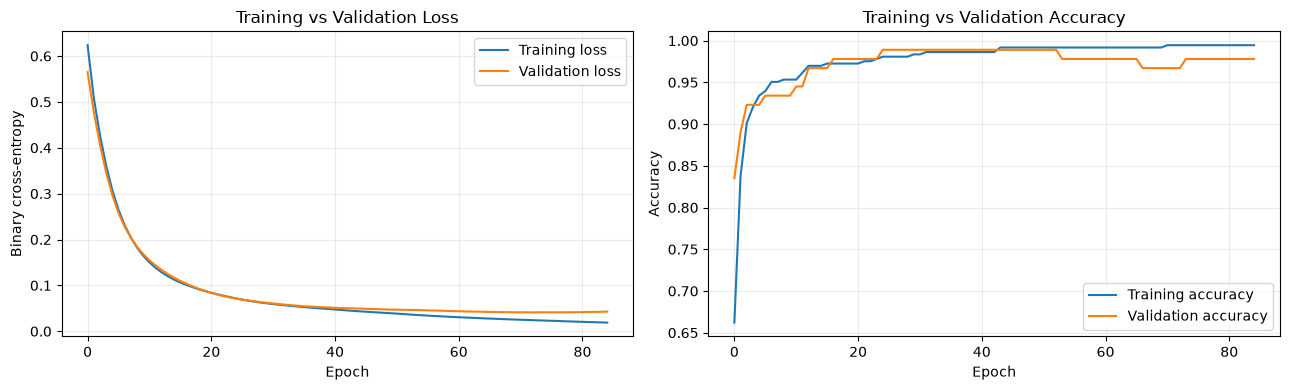

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 8. Model evaluation
The test set is held out from fitting and scaling. We report accuracy, precision, recall, F1-score and the confusion matrix, as required by the lab sheet. ROC-AUC is included as an additional metric.

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** among predictions for a class, the proportion that are correct.
- **Recall:** among actual members of a class, the proportion correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **Confusion matrix:** counts correct and incorrect predictions by actual and predicted class.

In [8]:
test_probabilities = model.predict(X_test_scaled, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions, zero_division=0))
print("Recall   :", recall_score(y_test, test_predictions, zero_division=0))
print("F1-score :", f1_score(y_test, test_predictions, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, test_probabilities))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["Malignant", "Benign"],
    zero_division=0
))

Accuracy : 0.9736842105263158
Precision: 0.9859154929577465
Recall   : 0.9722222222222222
F1-score : 0.9790209790209791
ROC-AUC  : 0.994047619047619

Classification report:
              precision    recall  f1-score   support

   Malignant       0.95      0.98      0.96        42
      Benign       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



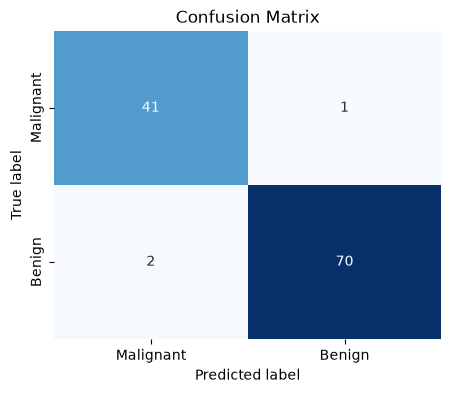

In [9]:
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix")
plt.show()

## 9. Interpretation of model performance
Use the printed test metrics and the curves above to discuss performance. A good accuracy value alone is not sufficient: inspect precision and recall for both classes because different types of classification errors have different implications.

Compare training and validation loss:
- Training loss much lower than validation loss may indicate overfitting.
- Both losses remaining high may indicate underfitting.
- Similar, decreasing curves suggest more consistent generalization, but the held-out test metrics are still needed.

## 10. Self-learning extension A – activation function experiment
To go beyond the minimum lab requirements, compare ReLU, tanh and sigmoid in the hidden layers while keeping the same train/test split, scaled data, architecture, optimizer and training budget. The output layer remains sigmoid for binary classification.

The test metrics may vary because neural-network training is stochastic. The experiment should be interpreted using the observed results, not by assuming one activation always wins.

In [10]:
activation_results = []

for activation in ["relu", "tanh", "sigmoid"]:
    tf.keras.utils.set_random_seed(SEED)
    experiment_model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(INPUT_NEURONS,)),
        tf.keras.layers.Dense(16, activation=activation),
        tf.keras.layers.Dense(8, activation=activation),
        tf.keras.layers.Dense(1, activation="sigmoid")
    ])
    experiment_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    experiment_model.fit(
        X_train_scaled, y_train,
        validation_split=0.20,
        epochs=60,
        batch_size=32,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=8, restore_best_weights=True
        )],
        verbose=0
    )
    probs = experiment_model.predict(X_test_scaled, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    activation_results.append({
        "Hidden activation": activation,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1-score": f1_score(y_test, preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probs)
    })

activation_comparison = pd.DataFrame(activation_results).sort_values("F1-score", ascending=False)
display(activation_comparison.round(4))

,Hidden activation,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,sigmoid,0.9737,0.9859,0.9722,0.9790,0.9947
0,relu,0.9649,0.9857,0.9583,0.9718,0.9947
1,tanh,0.9561,0.9855,0.9444,0.9645,0.9954


## 11. Self-learning extension B – regularization and early stopping
Dropout is a regularization technique. During training, it randomly sets a fraction of layer outputs to zero, which can discourage the network from relying too heavily on particular neurons. Early stopping ends training when validation loss stops improving and can restore the best weights.

This experiment compares a baseline network with a network that uses dropout. Both use the same data split and scaling. Dropout is active only during training.

In [11]:
def make_regularized_model(use_dropout):
    layers = [
        tf.keras.layers.Input(shape=(INPUT_NEURONS,)),
        tf.keras.layers.Dense(16, activation="relu")
    ]
    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.25))
    layers.append(tf.keras.layers.Dense(8, activation="relu"))
    if use_dropout:
        layers.append(tf.keras.layers.Dropout(0.25))
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))

    m = tf.keras.Sequential(layers)
    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return m

regularization_results = []
for label, use_dropout in [("Baseline", False), ("Dropout 0.25", True)]:
    tf.keras.utils.set_random_seed(SEED)
    m = make_regularized_model(use_dropout)
    h = m.fit(
        X_train_scaled, y_train,
        validation_split=0.20,
        epochs=100,
        batch_size=32,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=12, restore_best_weights=True
        )],
        verbose=0
    )
    p = m.predict(X_test_scaled, verbose=0).ravel()
    pred = (p >= 0.5).astype(int)
    regularization_results.append({
        "Experiment": label,
        "Epochs completed": len(h.history["loss"]),
        "Test accuracy": accuracy_score(y_test, pred),
        "Test F1-score": f1_score(y_test, pred, zero_division=0),
        "Final training loss": h.history["loss"][-1],
        "Final validation loss": h.history["val_loss"][-1]
    })

display(pd.DataFrame(regularization_results).round(4))

,Experiment,Epochs completed,Test accuracy,Test F1-score,Final training loss,Final validation loss
0,Baseline,85,0.9737,0.979,0.0188,0.0429
1,Dropout 0.25,100,0.9561,0.965,0.0321,0.0393


## 12. Conclusion
In this lab, a multilayer perceptron was designed and trained for binary classification. The workflow included dataset inspection, preprocessing, stratified train-test splitting, feature scaling, architecture selection, model compilation, training, parameter analysis and evaluation. The additional experiments explored how hidden-layer activation functions and dropout can affect model performance.

